<a href="https://colab.research.google.com/github/suavejavi/Data201-labs/blob/main/Assignments/Week8_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#DATA 201- Week 8 Homework

##Finding the Right Amount of Regularization

Javier Mantilla

#Loading the Dataset

In [1]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score



In [3]:
hitters = load_data('Hitters')
print('Original shape:', hitters.shape)
display(hitters.head())
print('Missing values:')
print(hitters.isna().sum().sort_values())

Original shape: (322, 20)


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


Missing values:
AtBat         0
Hits          0
HmRun         0
Runs          0
RBI           0
Walks         0
Years         0
CAtBat        0
CHits         0
CHmRun        0
CRuns         0
CRBI          0
CWalks        0
League        0
Division      0
PutOuts       0
Assists       0
Errors        0
NewLeague     0
Salary       59
dtype: int64


In [5]:
#remove the missing information
hitters = hitters.dropna(subset=['Salary']).copy()

#Set your features and target
X = hitters.drop(columns='Salary')
y = hitters['Salary']    # thousands of dollars

#define num/cat for later scaling and encoding
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print(category_cols)

#split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

#you can check how many rows went for each set
print(len(X), len(X_train), len(X_test))

['League', 'Division', 'NewLeague']
263 197 66


In [6]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols)
            ])

baseline = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', LinearRegression())
])

baseline.fit(X_train, y_train)

def measure(name, fitted_model):
    train_pred = fitted_model.predict(X_train)
    test_pred = fitted_model.predict(X_test)
    return {
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R²': r2_score(y_test, test_pred)
    }

results = [measure('Linear regression (no penalty)', baseline)]
display(pd.DataFrame(results).round(2))

,Model,Train RMSE,Test RMSE,Test R²
0,Linear regression (no penalty),289.33,357.05,0.41


#Part 1- Experiment with α (4 points)

In [16]:
alpha_examples = [0.1, 10, 100,]
rows = []
for kind, estimator in [('Lasso', Lasso(max_iter=30000))]:
    for a in alpha_examples:
        pipe = Pipeline([
            ('preprocess', make_preprocessor()),
            ('model', estimator.set_params(alpha=a))
        ])
        pipe.fit(X_train, y_train)

        #get the model's coefficients
        coefs = pipe.named_steps['model'].coef_

        #each time the loop runs, we add one dictionary to the list "rows".
        rows.append({
             'Model': kind,'Chosen Values of Alpha': a,
            'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6)), #count nonzero coefficients
            'Training RMSE': np.sqrt(mean_squared_error(y_train, pipe.predict(X_train))),
            'Test RMSE': np.sqrt(mean_squared_error(y_test, pipe.predict(X_test)))
        })
alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))

,Model,Chosen Values of Alpha,Nonzero coefficients,Training RMSE,Test RMSE
0,Lasso,0.1,19,289.38,356.83
1,Lasso,10.0,9,303.10,381.84
2,Lasso,100.0,5,341.39,395.12


#Questions:
1. As α increases, what happens to the number of retained predictors?

As α increases, the number of retained predictors goes down.

2. Does a smaller number of predictors always lead to a lower test RMSE?

No, a smaller number of predictors does not always lead to a lower test RMSE, this is shown by our table as even tho the number of retained preditctors goes down, our Test RMSE keeps increasing, which shows that a smaller number of predictors doesn't always lead to a lower Test RMSE.

#Part 2 - Visualize and interpret (3 points)

Create a graph showing α versus Test RMSE for the three models.

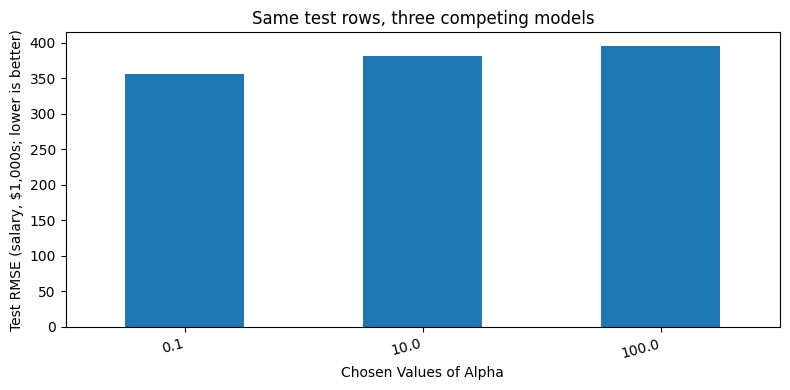

In [17]:
ax = alpha_table.plot(kind='bar', x='Chosen Values of Alpha', y='Test RMSE', legend=False, figsize=(8, 4))
ax.set_ylabel('Test RMSE (salary, $1,000s; lower is better)')
ax.set_title('Same test rows, three competing models')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

#Questions:

1. Which α produces the lowest test RMSE among the three values?

Out of all of the three α's, the alpha of 0.1 one produces the lowest test RMSE out of all of the three values, with a test RMSE around 350.

2. Which α appears to cause the most underfitting? Explain using bias.

I think the alpha of 100 causes the most underfitting. The lasso reduces coefficents that don't belong as the alpha increases, which causes our model to be very rigid, or with high bias. Since our model is very rigid, it does not capture the patterns in the dataset, which causes our model to be too simple and perform bad on the training dataset and testing dataset, which causes the most underfitting out of three α's.

3. Why might a model with higher training RMSE produce lower test RMSE?

I believe that a model with a higher training RMSE could produce a lower testing RMSE because of regularization. For example with Lasso, lasso uses regularization by removing coefficients that are not important. Since Lasso removes coefficietns, when it learns the training data it may underfit, because lasso is created to not overfit the data, because it remove the predictors that arent important. So, when it learns the training data, it will have a higher training RMSE than testing RMSE, because it will not learn all of the patterns in the training, (underfitting), but perform better on the testing dataset, therefore having a lower testing RMSE than training RMSE.

#Part 3- Model interpretation (3 points)
Using your results from Part 1:
1. Identify two predictors that Lasso sets to zero at α = 100.


2. Does setting their coefficients to zero prove that these predictors have no relationship
with salary? Explain.


3. If two models have very similar test RMSE but one uses fewer predictors, which would
you prefer? Explain your answer in terms of interpretability and predictive performance.

In [19]:
feature_names = baseline.named_steps['preprocess'].get_feature_names_out()

lasso_a_100 = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', Lasso(alpha=100, max_iter=30000))
])

lasso_a_100.fit(X_train, y_train)

coef_table = pd.DataFrame({
    'Feature': feature_names,
    'OLS': baseline.named_steps['model'].coef_,
    'Lasso where our alpha = 100': lasso_a_100.named_steps['model'].coef_
})

display(coef_table.round(2))

,Feature,OLS,Lasso where our alpha = 100
0,num__AtBat,-252.65,0.00
1,num__Hits,379.23,76.59
2,num__HmRun,64.67,0.00
3,num__Runs,-82.33,0.00
4,num__RBI,-52.67,0.00
5,num__Walks,113.43,16.17
6,num__Years,35.91,0.00
7,num__CAtBat,-318.63,0.00
8,num__CHits,-136.22,0.00
9,num__CHmRun,-50.89,0.00


1. Identify two predictors that Lasso sets to zero at α = 100.

Two predictors that Lasso sets to zero when our alpha is 100 is num__RBI and num_HmRun.

2. Does setting their coefficients to zero prove that these predictors have no relationship with salary? Explain.

No, setting their coeficients to zero doesn't prove that these predictors have no relationship with salary because Lasso reduces features to 0 because they are corellated with other features, for exampl,e at bats and home runs have a positive correlation, the more at bats,the more home runs. So, it does not mean the predictor has no relationship with salary, moreso it has corelation with other features.

3. If two models have very similar test RMSE but one uses fewer predictors, which would you prefer? Explain your answer in terms of interpretability and predictive performance.

Out of the two models, I would choose the one that has fewer predictors. Like you always say, the simpler model is most likely the better one, it takes less time, it runs better on the cloud, and it is healthier for your machine. Also, it is more efficient, which is good when having to run multiple lines of code.

#Part 4 - Choosing the Right Regression Model (4 points)

For each scenario, choose Ridge (L2), Lasso (L1), Ordinary Linear Regression, or Not Sure. Explain your choice in 2-3 sentences, considering the number of predictors, model complexity,interpretability, and potential overfitting.

- Scenario A: A researcher has data from 80 patients with 200 medical measurements. The goal is to identify a small number of measurements that may be useful for predicting disease severity.

For scenario a, the model I would choose would be Lasso. This is because Lasso trims down predictors, and the researcher wants to find a small number of measurements. I do think that we should use cross validation on our alpha to choose the best one, rather than just guessing and checking.

- Scenario B: A company wants to predict employee salaries using 40 predictors. Many predictors are strongly correlated, and the company believes most contain useful information. Keeping all predictors is not a concern.

For scenario b, the model I would choose would be Ridge. First off, I think Ridge is the best because it does not fully remove predictors that are correlated to one another, which we know we have a lot of. We wouldn't want to use Lasso for this exact reason, as Lasso cuts out predictors that are correlated, which means we coukd be missing out on potential insights.

- Scenario C: A researcher has 10,000 observations and only three predictors.The
relationship appears approximately linear, and the researcher wants a simple model that is easy to interpret.

For scenario c, the best model is ordinary linear regression. Ridge could also work, because we don't know if overfitting is an issue, and the features are correlated to one another, but we don't want to remove them.Lasso could work also if overfitting could be an issue, and the features are correlated, but we do want to remove them. Knowing all of this, ordinary linear regression would still be the best because the researcher wants a simple model, and ordinary linear regression is the simplest out of the three.

- Scenario D: A company has 500 observations and 25 predictors. It is unclear how many predictors are useful or how strongly they are correlated. The company wants the most accurate predictions possible.

For scenario d, I think the best model would be up to what our cross validation of the hyperparemeters gives us. We know that we have predictors, but we don't know if they're useful or how strongly they're correlated. So, with cross validation, if many of the predictors are correlated, and useful, ridge may perform best. If some predictors are noise, and the model removes the ones that are correlated, than lasso is the best. So, I feel like I really am not sure on this one, because I don't want to risk it and pick in advance before what the cross validation and each model evaluation tells me.

